# Single-Sérsic validation

This notebook runs a compact end-to-end validation on a controlled synthetic single-Sérsic galaxy.

All numerical settings live in `configs/mock_pipeline.yaml`; the notebook only calls the public BayMorph API.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd

from baymorph import (
    load_resolved_config,
    make_observation_from_config,
    run_image_preparation,
    run_real_fit,
)

In [2]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

CONFIG_PATH = PROJECT_ROOT / "configs" / "mock_pipeline.yaml"
config = load_resolved_config(CONFIG_PATH)

config["object"]["name"] = "single_sersic_validation"
config["data"]["image_path"] = "runs/single_sersic_validation/input/single_sersic_validation.fits"
config["outputs"]["root"] = "runs"
config["fit"]["models"] = ["single_sersic"]

In [3]:
observation = make_observation_from_config(config)
image_path = Path(config["data"]["image_path"])
image_path.parent.mkdir(parents=True, exist_ok=True)
observation.to_fits(image_path, overwrite=config["outputs"]["overwrite"])

print(f"Synthetic FITS written to: {image_path}")

Synthetic FITS written to: runs/single_sersic_validation/input/single_sersic_validation.fits


In [4]:
preparation = run_image_preparation(config)
fit = run_real_fit(config)

iter: 19293 | +300 | bound: 64 | nc: 1 | ncall: 529202 | eff(%):  3.704 | loglstar:   -inf < -25761.322 <    inf | logz: -25820.920 +/-  0.428 | dlogz:  0.000 >  0.010                               

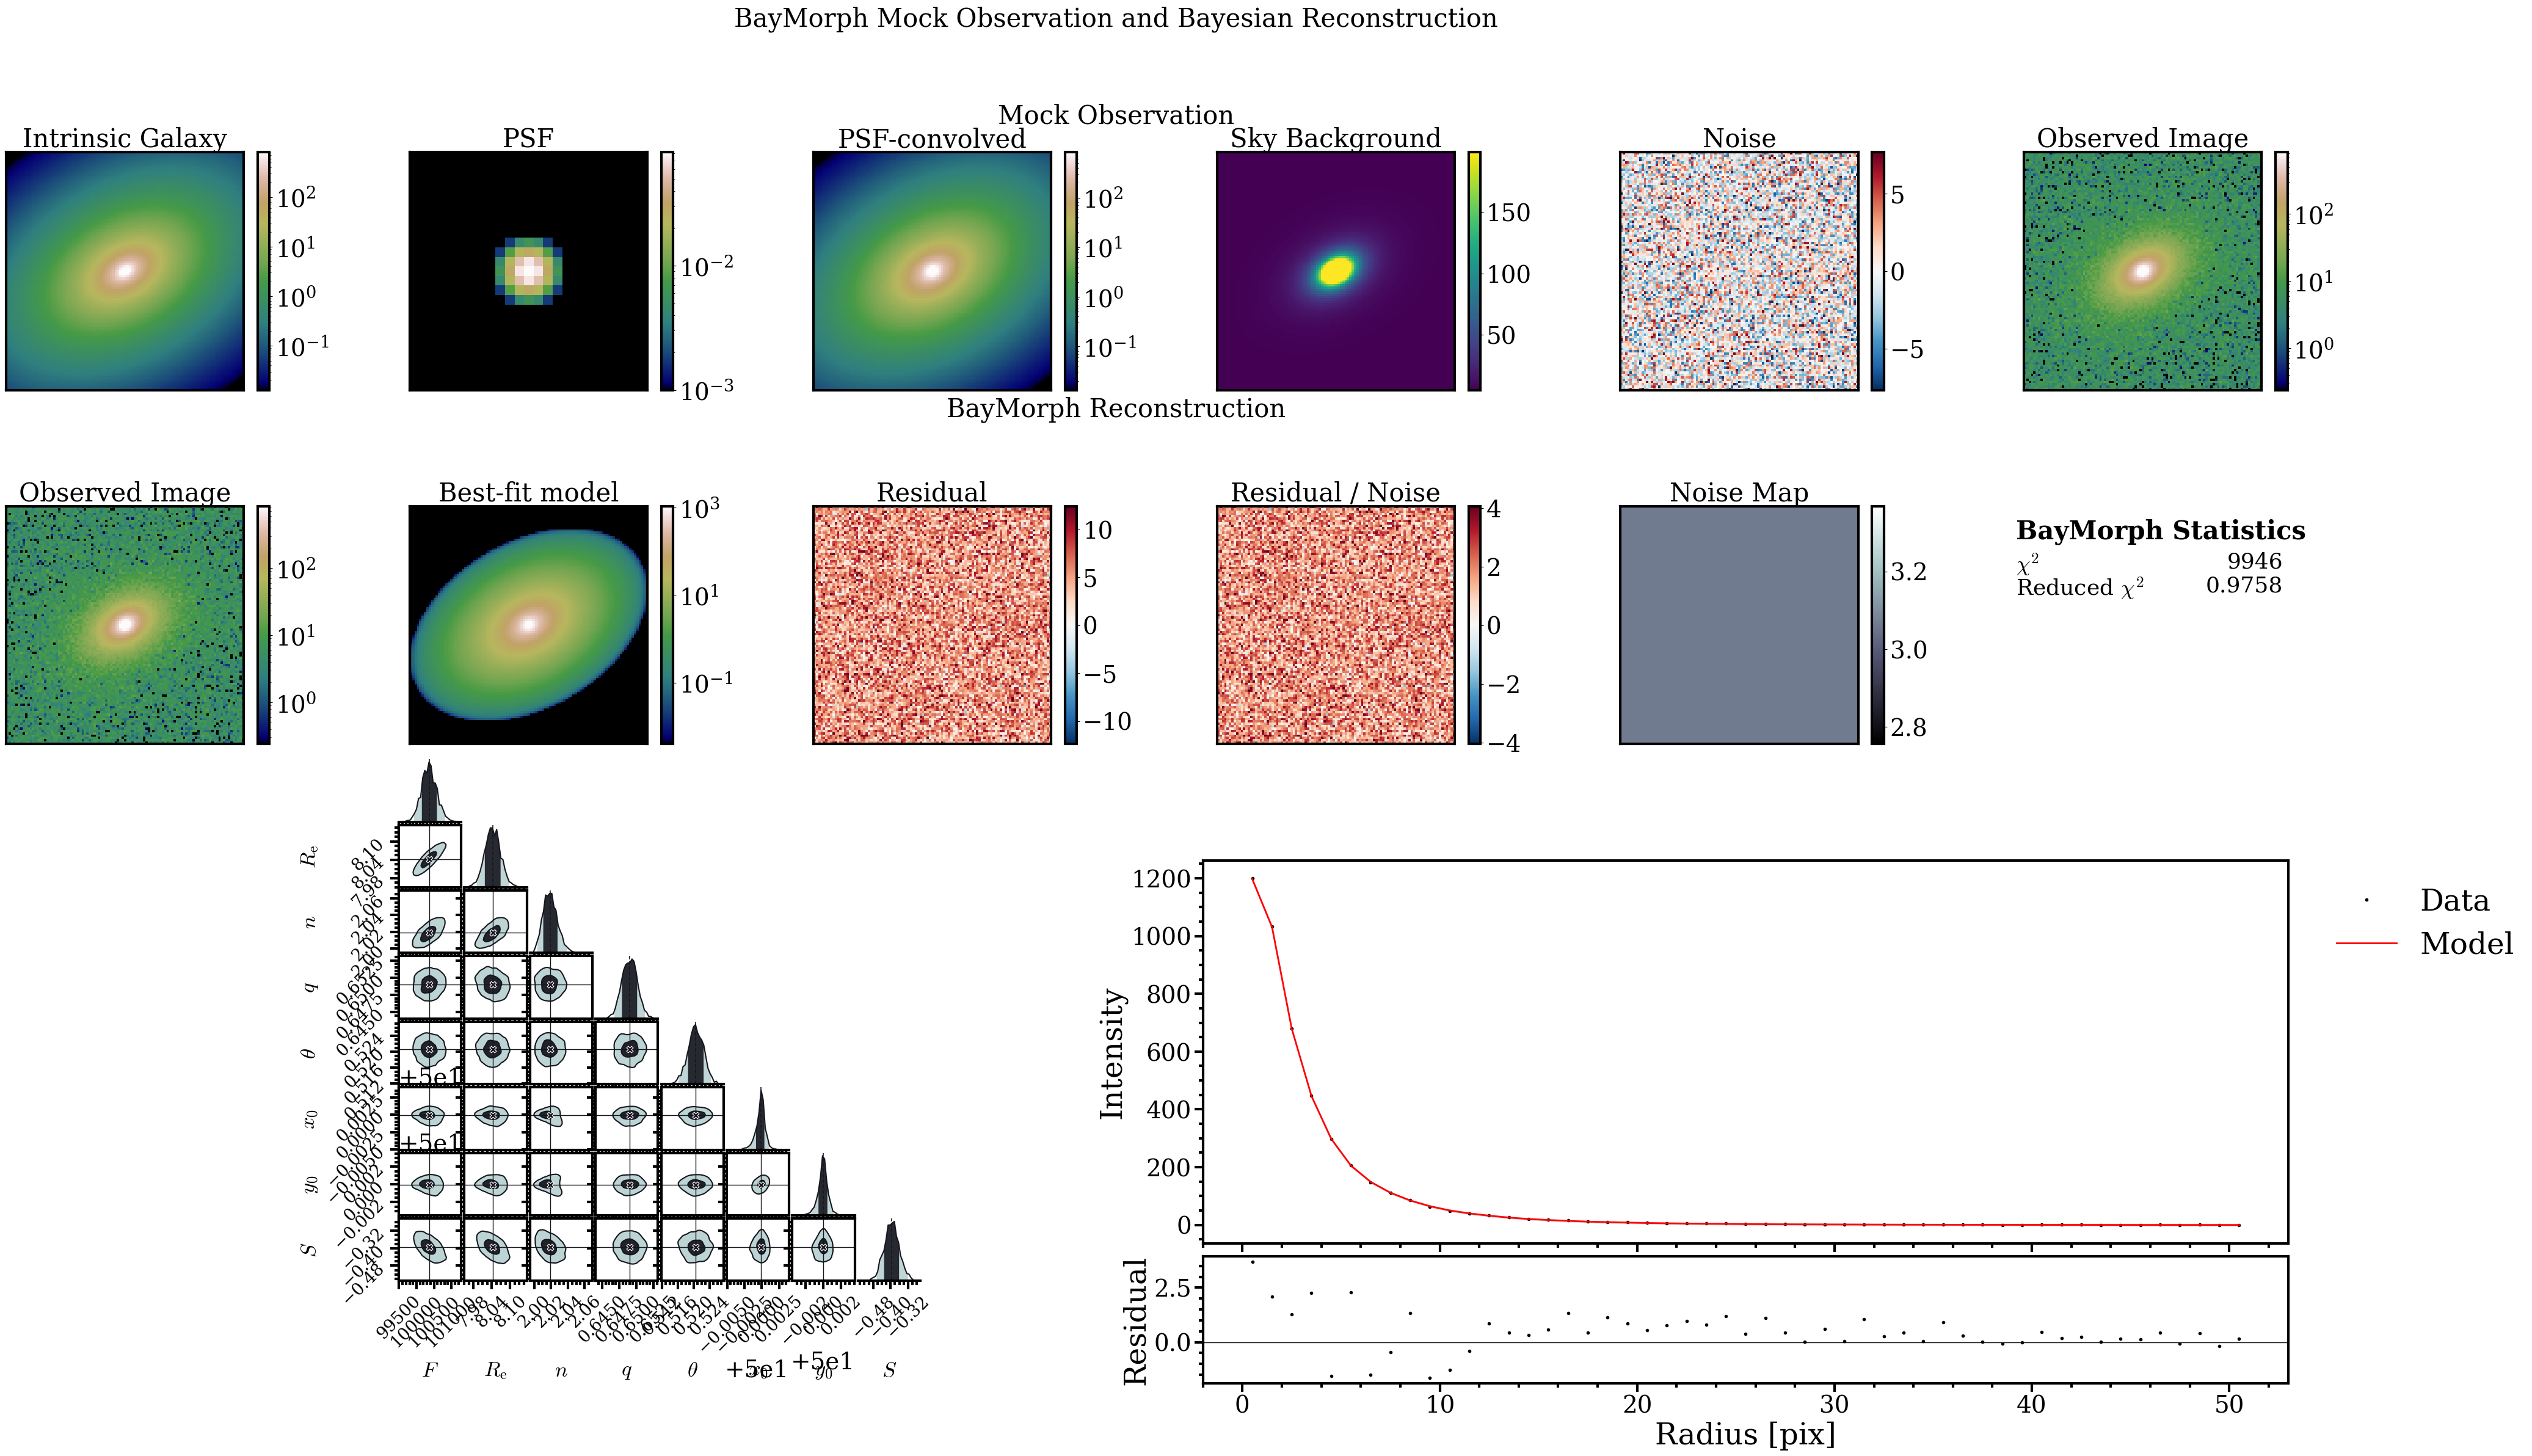

(<Figure size 4000x2400 with 90 Axes>,
 array([[<Axes: title={'center': 'Intrinsic Galaxy'}>,
         <Axes: title={'center': 'PSF'}>,
         <Axes: title={'center': 'PSF-convolved'}>,
         <Axes: title={'center': 'Sky Background'}>,
         <Axes: title={'center': 'Noise'}>,
         <Axes: title={'center': 'Observed Image'}>],
        [<Axes: title={'center': 'Observed Image'}>,
         <Axes: title={'center': 'Best-fit model'}>,
         <Axes: title={'center': 'Residual'}>,
         <Axes: title={'center': 'Residual / Noise'}>,
         <Axes: title={'center': 'Noise Map'}>, <Axes: >]], dtype=object))

In [5]:
fit.report(observation)

In [6]:
truth = observation.truth
rows = []

for name in ["flux", "re", "n", "q", "theta", "x0", "y0"]:
    truth_value = truth[name]
    fit_value = fit.best_parameters[name]

    if name == "theta":
        truth_value = truth_value * 180.0 / np.pi
        fit_value = fit_value * 180.0 / np.pi

    rows.append(
        {
            "parameter": name,
            "truth": truth_value,
            "best_fit": fit_value,
            "best_fit_minus_truth": fit_value - truth_value,
        }
    )

pd.DataFrame(rows)

,parameter,truth,best_fit,best_fit_minus_truth
0,flux,100000.00,100118.421863,1.184219e+02
1,re,8.00,8.016850,1.684957e-02
2,n,2.00,2.002347,2.347467e-03
3,q,0.65,0.649419,-5.811701e-04
4,theta,30.00,29.814713,-1.852874e-01
5,x0,50.00,49.999999,-5.770444e-07
6,y0,50.00,49.999994,-5.927884e-06


## Summary

The report compares the injected mock observation with the BayMorph reconstruction and shows the posterior and radial-profile diagnostics using the public `RealFitProducts` API.